<a href="https://colab.research.google.com/github/yamenetoo/Fast-Face-tracking/blob/main/notebooks/colab_simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# fastfacetrack: simulation on Colab

This notebook runs the complete pipeline on **simulated video with known ground truth**, so no private footage is needed.

| Step | What happens |
|---|---|
| 1 | Install the package, choose the settings |
| 2 | Build a bank of "people" from public photos and render a synthetic video of one of them |
| 3 | Extract faces from one clip per person with the UltraLight detector |
| 4 | Cluster the faces without labels (does k-means recover the people?) |
| 5 | Train five classifiers: logistic regression, random forest, decision tree, ANN, CNN |
| 6 | Test them on a new video with several people, recording detection time and target presence |
| 7 | Compare detectors and models, and optionally run the full multi-video experiment |

Runtime: CPU is enough (about 10 minutes for the whole notebook).

## 1. Setup

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("fastfacetrack") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "git+https://github.com/yamenetoo/Fast-Face-tracking.git"])

import warnings, os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
warnings.filterwarnings("ignore")

from pathlib import Path
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt

import fastfacetrack as fft
from fastfacetrack.clustering import cluster_faces, cluster_purity, montage
from fastfacetrack.evaluation import run_detector, load_truth
from fastfacetrack.report import annotate_frames, plot_model_comparison, plot_timeline

OUT = Path("sim_output"); OUT.mkdir(exist_ok=True)
SEED = 0
TRAIN_FRAMES = 90        # frames per training clip (one person per clip)
TEST_FRAMES = 300
N_TRAIN_OTHERS = 4       # people seen in training besides the target
EPOCHS = 40
pd.set_option("display.width", 160); pd.set_option("display.precision", 3)
print("fastfacetrack", fft.__version__)

fastfacetrack 1.0.0


## 2. Identities and a simulated video

Every face the detector finds in three public group photos becomes one "person". The target is one of them; the others are the people the classifier must tell apart from the target. The video is a normal MP4 file (moving background, people drifting, changing size, rotation, lighting, blur, entering and leaving) with a JSON file holding the exact face boxes.

9 people | target: person_004 | seen in training: ['person_005', 'person_002', 'person_006', 'person_003'] | only at test time: ['person_008', 'person_007']


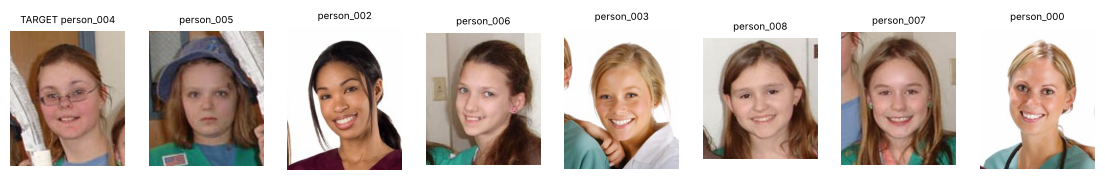

In [2]:
detector = fft.make_detector("ultralight")                 # downloads the 1 MB ONNX model on first use
bank = fft.IdentityBank.demo(detector, cache_dir=OUT / "demo_photos", min_width=60)
rng = np.random.default_rng(SEED)
names = [i.name for i in bank.identities]; rng.shuffle(names)
target, seen = names[0], names[1:1 + N_TRAIN_OTHERS]
unseen = names[1 + N_TRAIN_OTHERS:1 + N_TRAIN_OTHERS + 2]
print(f"{len(bank)} people | target: {target} | seen in training: {seen} | only at test time: {unseen}")

fig, ax = plt.subplots(1, len(names[:8]), figsize=(14, 2.2))
for a, n in zip(ax, names[:8]):
    a.imshow(cv2.cvtColor(bank.by_name(n).patch, cv2.COLOR_BGR2RGB)); a.axis("off")
    a.set_title(("TARGET " if n == target else "") + n, fontsize=7)
plt.show()

## 3. Face extraction (one clip per person)

person_004    90 faces (target)


person_005    90 faces 


person_002    90 faces 


person_006    90 faces 


person_003    90 faces 


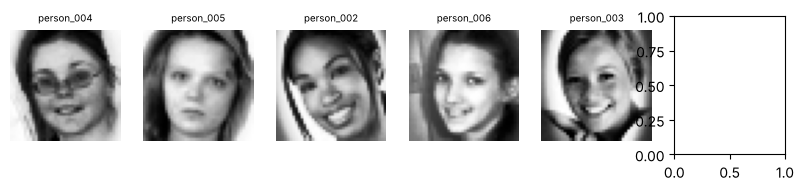

In [3]:
sets = {}
for k, name in enumerate([target] + seen):
    video = OUT / f"train_{name}.mp4"
    cfg = fft.SimulationConfig(n_frames=TRAIN_FRAMES, seed=SEED * 100 + k, presence_probability=1.0)
    fft.simulate_video(bank, name, [], video, cfg, target_always_present=True)
    sets[name] = fft.extract_faces(video, detector)
    print(f"{name:11s} {len(sets[name]):4d} faces", "(target)" if name == target else "")

fig, ax = plt.subplots(1, 6, figsize=(10, 1.8))
for a, n in zip(ax, list(sets)[:6]):
    a.imshow(sets[n].faces[len(sets[n]) // 2], cmap="gray"); a.axis("off"); a.set_title(n, fontsize=7)
plt.show()

## 4. Clustering without labels

If the faces of different people form separate groups, a person can be isolated without labelling anything by hand: cluster, look at the montage (one row per cluster) and pick the target's cluster.

purity 1.000  |  silhouette 0.458


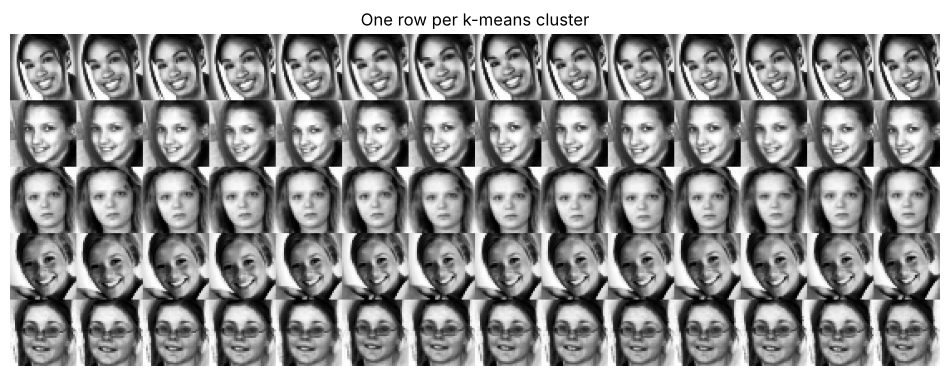

In [4]:
all_faces = np.concatenate([s.faces for s in sets.values()])
truth_ids = np.concatenate([[n] * len(s) for n, s in sets.items()])
labels, info = cluster_faces(all_faces, len(sets), features="hog", seed=SEED)
print(f"purity {cluster_purity(labels, truth_ids):.3f}  |  silhouette {info['silhouette']:.3f}")
plt.figure(figsize=(12, 6)); plt.imshow(montage(all_faces, labels, per_cluster=14), cmap="gray"); plt.axis("off")
plt.title("One row per k-means cluster"); plt.show()

## 5. Train the five classifiers

In [5]:
faces, y, groups = fft.make_dataset([sets[target]], [sets[n] for n in seen])
classifiers, report = fft.train_models(faces, y, groups, fft.MODEL_NAMES, features="hog", seed=SEED, epochs=EPOCHS)
report[["model", "kind", "parameters", "train_seconds", "n_train", "n_val", "val_accuracy", "val_precision", "val_recall", "val_f1"]]

,model,kind,parameters,train_seconds,n_train,n_val,val_accuracy,val_precision,val_recall,val_f1
0,logreg,classical,NaN,0.07,360,90,1.000,1.000,1.0,1.000
1,rf,classical,NaN,0.75,360,90,1.000,1.000,1.0,1.000
2,tree,classical,NaN,0.05,360,90,0.967,1.000,0.9,0.947
3,ann,deep,213249.0,5.71,360,90,1.000,1.000,1.0,1.000
4,cnn,deep,25409.0,3.91,360,90,0.333,0.333,1.0,0.500


## 6. Test on a new video

The test video shows the target together with two people seen in training and two people the classifiers have never seen, with new backgrounds and trajectories. For every frame the detector runs once; each classifier then labels the detected faces. Recorded per frame: detection time, classification time and whether the target is predicted present.

In [6]:
test_video = OUT / "test.mp4"
actors = seen[:2] + unseen
fft.simulate_video(bank, target, actors, test_video, fft.SimulationConfig(n_frames=TEST_FRAMES, seed=SEED * 100 + 77))
summary, per_frame = fft.evaluate_video(test_video, detector, classifiers, test_video.with_suffix(".truth.json"))
cols = ["model", "det_precision", "det_recall", "det_f1", "frame_accuracy", "face_detection_recall",
        "detect_ms", "classify_ms", "fps", "first_hit_delay_frames"]
summary[cols]

,model,det_precision,det_recall,det_f1,frame_accuracy,face_detection_recall,detect_ms,classify_ms,fps,first_hit_delay_frames
0,logreg,0.873,1.000,0.932,0.977,1.0,9.499,0.778,97.307,0
1,rf,0.977,0.875,0.923,0.977,1.0,9.499,17.501,37.037,0
2,tree,0.297,0.917,0.449,0.803,1.0,9.499,0.190,103.208,0
3,ann,1.000,0.812,0.897,0.970,1.0,9.499,5.235,67.867,0
4,cnn,0.079,1.000,0.146,0.207,1.0,9.499,10.956,48.888,0


In [7]:
best = summary.sort_values("det_f1", ascending=False).iloc[0]["model"]
print("best model on this video:", best)
plot_timeline(per_frame, best, OUT / "timeline.png"); plt.figure(figsize=(11, 3)); plt.imshow(plt.imread(OUT / "timeline.png")); plt.axis("off"); plt.show()

frames = run_detector(test_video, detector)
truth = load_truth(test_video.with_suffix(".truth.json"))
present = [f for f, t in truth.items() if any(x["target"] for x in t)]
pick = [present[int(i)] for i in np.linspace(0, len(present) - 1, 6)]
annotate_frames(test_video, frames, classifiers[best], OUT / "annotated.png", pick)
plt.figure(figsize=(13, 6)); plt.imshow(cv2.cvtColor(cv2.imread(str(OUT / "annotated.png")), cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title("green = classified as target, red = other (probability shown)"); plt.show()

best model on this video: logreg


## 7. Detectors compared

In [8]:
tables = []
for name in ["ultralight", "ultralight-slim", "haar"]:
    s, _ = fft.evaluate_video(test_video, fft.make_detector(name), classifiers, test_video.with_suffix(".truth.json"))
    tables.append(s)
results = fft.combine_results(tables, OUT / "detector_comparison.csv")
results[["detector", "model", "det_f1", "face_detection_recall", "detect_ms", "classify_ms", "fps"]]

,detector,model,det_f1,face_detection_recall,detect_ms,classify_ms,fps
0,ultralight-rfb-320,logreg,0.932,1.0,8.556,0.716,107.852
1,ultralight-rfb-320,rf,0.923,1.0,8.556,15.569,41.450
2,ultralight-rfb-320,tree,0.449,1.0,8.556,0.422,111.381
3,ultralight-rfb-320,ann,0.897,1.0,8.556,4.109,78.957
4,ultralight-rfb-320,cnn,0.146,1.0,8.556,9.759,54.600
5,ultralight-slim-320,logreg,0.920,1.0,8.037,0.520,116.862
6,ultralight-slim-320,rf,0.884,1.0,8.037,14.121,45.131
7,ultralight-slim-320,tree,0.472,1.0,8.037,0.231,120.951
8,ultralight-slim-320,ann,0.800,1.0,8.037,4.412,80.330
9,ultralight-slim-320,cnn,0.148,1.0,8.037,10.247,54.694


## 8. Optional: the full experiment

`run_experiment` repeats the steps above with more people and several test videos, and writes all tables and figures (the numbers in the repository README come from this run with its default settings). Set `RUN_FULL = True` to run it (about 15 minutes on Colab CPU).

In [9]:
RUN_FULL = False
if RUN_FULL:
    full = fft.run_experiment(fft.ExperimentConfig(out_dir=str(OUT / "full")))
    display(full["aggregate"].reset_index().filter(regex="detector|model|det_f1|detect_ms|classify_ms"))

## Using your own footage

```python
det  = fft.make_detector("ultralight")
fs   = fft.extract_faces("target.mp4", det)          # faces of the person to find
oth  = fft.extract_faces("others.mp4", det)          # everybody else
X, y, g = fft.make_dataset([fs], [oth])
models, report = fft.train_models(X, y, g)
summary, per_frame = fft.evaluate_video("test.mp4", det, models)   # no truth file needed
```